# 04 - Results, plots and summary table

In [1]:
import json, glob, os
import matplotlib.pyplot as plt
import revllm
GiB = 2**30
R = {os.path.basename(p)[:-5]: json.load(open(p)) for p in sorted(glob.glob("results/0*_*.json"))
     if "history" in json.load(open(p))}
for r in R.values():  # recompute with the final metric definition (mean over last 10% of tokens)
    r["final_train_loss"] = revllm.final_train_loss(r["history"])
main = [k for k in R if k.startswith(("01_", "02_reversible", "03_"))]
print("| run | arch | batch (seq x 512) | steps | final train loss | final val loss | tokens/s | peak mem (GiB) | time (min) |")
print("|---|---|---|---|---|---|---|---|---|")
for k in main + [k for k in R if k.startswith("02_screen")]:
    r = R[k]
    print(f"| {k} | {r['model']['arch']} | {r['train']['batch_size']} | {r['steps']} | {r['final_train_loss']:.4f} | "
          f"{r['final_val_loss']:.4f} | {r['tokens_per_sec']:,.0f} | {r['peak_mem_bytes']/GiB:.2f} | {r['train_time_s']/60:.1f} |")

| run | arch | batch (seq x 512) | steps | final train loss | final val loss | tokens/s | peak mem (GiB) | time (min) |
|---|---|---|---|---|---|---|---|---|
| 01_baseline_standard_B32 | standard | 32 | 3051 | 4.6275 | 4.6310 | 17,012 | 7.31 | 49.0 |
| 02_reversible_momentum_B32 | momentum | 32 | 3051 | 4.7048 | 4.7126 | 13,857 | 0.80 | 60.1 |
| 03_reversible_momentum_maxB1528 | momentum | 1528 | 63 | 7.3577 | 7.3679 | 9,973 | 39.95 | 82.2 |
| 02_screen_coupling | coupling | 32 | 122 | 6.9792 | 7.1212 | 14,245 | 0.78 | 2.3 |
| 02_screen_euler | euler | 32 | 122 | 7.5029 | 7.6188 | 6,115 | 0.71 | 5.4 |
| 02_screen_midpoint | midpoint | 32 | 122 | 6.9757 | 7.1142 | 13,722 | 0.80 | 2.4 |
| 02_screen_momentum | momentum | 32 | 122 | 6.9668 | 7.1092 | 13,195 | 0.80 | 2.5 |
| 02_screen_standard | standard | 32 | 122 | 6.9996 | 7.1365 | 16,835 | 7.31 | 2.0 |


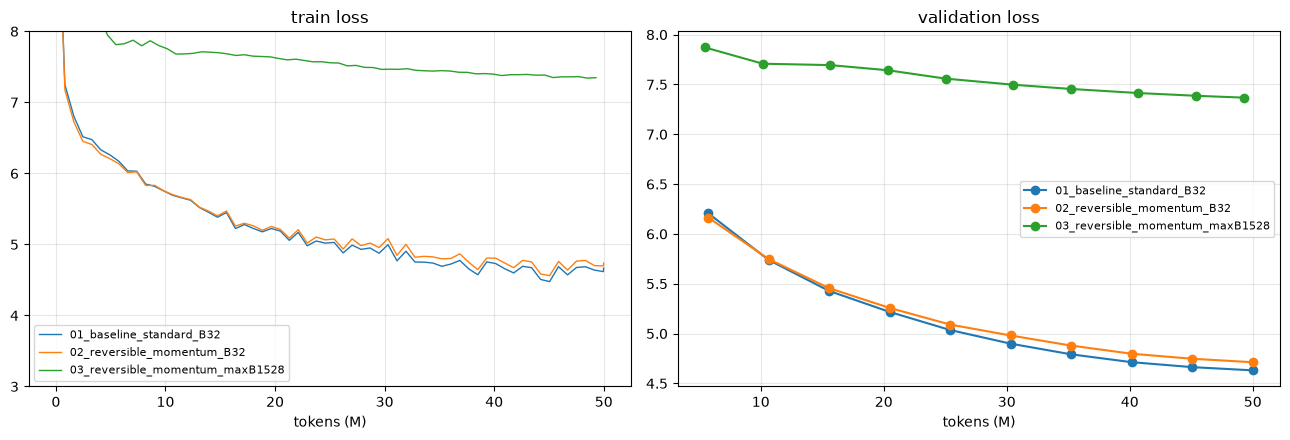

In [2]:
os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k in main:
    h, e = R[k]["history"], R[k]["evals"]
    ax[0].plot([t/1e6 for t in h["tokens"]], h["loss"], label=k, lw=1)
    ax[1].plot([t/1e6 for t in e["tokens"]], e["val_loss"], "o-", label=k)
for a, t in zip(ax, ["train loss", "validation loss"]):
    a.set_xlabel("tokens (M)"); a.set_title(t); a.grid(alpha=.3); a.legend(fontsize=8)
ax[0].set_ylim(3, 8)
plt.tight_layout(); plt.savefig("figures/loss_curves.png", dpi=130); plt.show()

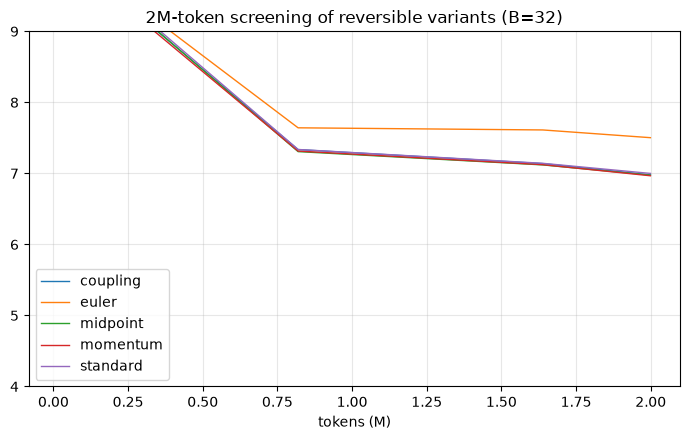

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in [k for k in R if k.startswith("02_screen")]:
    h = R[k]["history"]
    ax.plot([t/1e6 for t in h["tokens"]], h["loss"], label=R[k]["model"]["arch"], lw=1)
ax.set_ylim(4, 9); ax.set_xlabel("tokens (M)"); ax.set_title("2M-token screening of reversible variants (B=32)")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.savefig("figures/screening.png", dpi=130); plt.show()

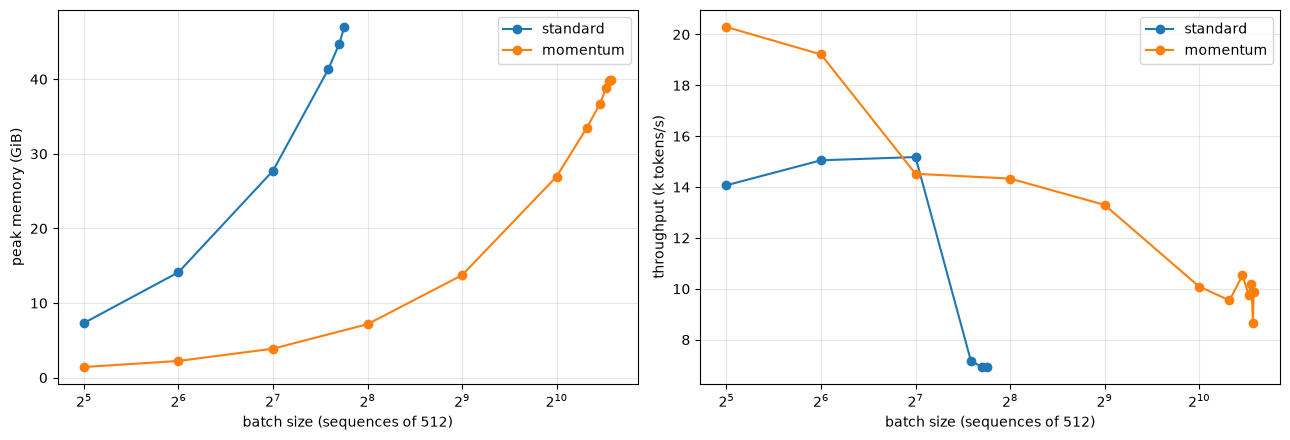

{'standard': 216, 'momentum': 1528}


In [4]:
S = json.load(open("results/03_max_batch_search.json"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for arch, s in S.items():
    ok = sorted([t for t in s["trials"] if t["ok"]], key=lambda t: t["B"])
    ax[0].plot([t["B"] for t in ok], [t["peak_mem_bytes"]/GiB for t in ok], "o-", label=arch)
    ax[1].plot([t["B"] for t in ok], [t["tokens_per_sec"]/1e3 for t in ok], "o-", label=arch)
ax[0].set_ylabel("peak memory (GiB)"); ax[1].set_ylabel("throughput (k tokens/s)")
for a in ax: a.set_xscale("log", base=2); a.set_xlabel("batch size (sequences of 512)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig("figures/batch_scaling.png", dpi=130); plt.show()
print({a: s["max_batch"] for a, s in S.items()})